In [1]:
! pip install pillow tensorflow


[notice] A new release of pip is available: 25.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd 
import PIL


import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.models import Sequential

In [3]:
import pathlib
import math
import unicodedata

In [4]:
# Mentor yêu cầu: train và test CHỈ với Set_B
TEN_SET = "Set_B"
DUOI_ANH = {".jpg", ".jpeg", ".png", ".bmp", ".gif"}

datatrain_dir = pathlib.Path("./" + TEN_SET + "/Train")
datatest_dir = pathlib.Path("./" + TEN_SET + "/Test")
datatrain_dir, datatest_dir

(WindowsPath('Set_B/Train'), WindowsPath('Set_B/Test'))

In [5]:
# các loài hoa trong tập train (tên thư mục, vd "3 - Hoa mai")
ten_lop_train = sorted(d.name for d in datatrain_dir.iterdir() if d.is_dir())

def chuan_hoa(s):
    """viết thường, bỏ dấu, bỏ khoảng trắng / số / ký tự đặc biệt: "Hoa Mai 2" -> "hoamai" """
    s = unicodedata.normalize("NFD", s.lower()).replace("đ", "d")
    return "".join(ch for ch in s if ch.isalpha())

def loai_that(p):
    """Loài thật của 1 hình test, lấy từ tên file:
       - có số ở đầu (vd "13_Hoa oi 015.jpg") -> theo số
       - không có số (vd "Hoa mai.jpg")        -> so tên file với tên loài trong tập train"""
    dau = p.name.split("_")[0]
    if dau.isdigit():
        return dau
    ten = chuan_hoa(p.stem)
    khop = [lop for lop in ten_lop_train if chuan_hoa(lop.split(" - ", 1)[-1]) in ten]
    return max(khop, key=len).split(" ")[0] if khop else None

# sắp xếp hình test theo loài (hình cùng loài đứng cạnh nhau)
def so_thu_tu(p):
    so = loai_that(p)
    return (int(so) if so else 10**9, p.name)

testList = sorted((p for p in datatest_dir.iterdir() if p.suffix.lower() in DUOI_ANH), key=so_thu_tu)
# ảnh train nằm trong các thư mục con theo từng loại hoa
trainlist = sorted(datatrain_dir.glob('*/*'))
len(testList) , len(trainlist)

(26, 50)

Set_B\Train\12 - Hong tu cau\Hong tu cau 003.jpg


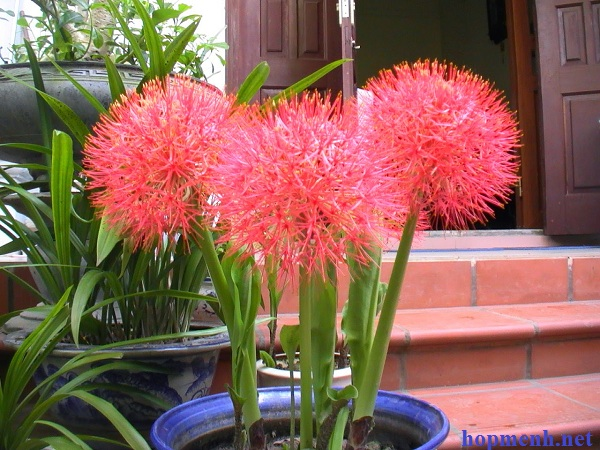

In [6]:
print(trainlist[0])
PIL.Image.open(trainlist[0])

In [7]:
#Tham số để chỉnh sửa hình
batch_size = 12
img_height = 224
img_width = 224
tf.keras.utils.set_random_seed(123)  # để mỗi lần chạy cho kết quả giống nhau

In [8]:
# Dùng TOÀN BỘ ảnh để train (không tách validation),
# vì có loài chỉ có 5-6 ảnh, bớt đi 20% là model học không đủ
train_ds = tf.keras.utils.image_dataset_from_directory(
  datatrain_dir,
  seed=123,
  image_size=(img_height, img_width),
  batch_size=batch_size)

Found 50 files belonging to 6 classes.


In [9]:
class_names = train_ds.class_names
print(class_names)

['12 - Hong tu cau', '15 - Lan hac vy', '20 - Hoa long den', '3 - Hoa mai', '6 - Hoa do quyen', '9 - Hoa sung']


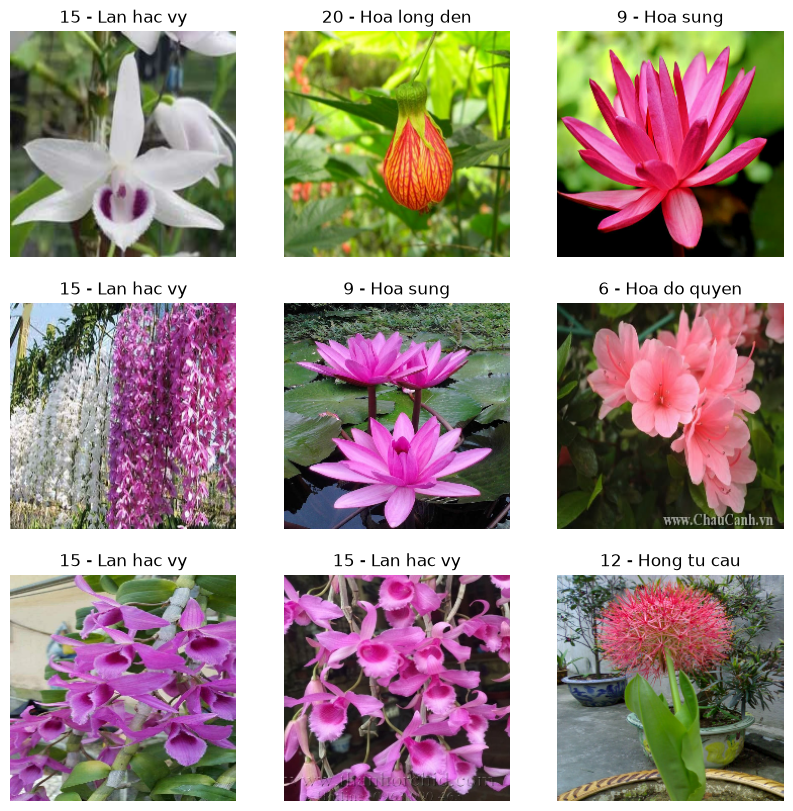

In [10]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 10))
for images, labels in train_ds.take(1):
  for i in range(9):
    ax = plt.subplot(3, 3, i + 1)
    plt.imshow(images[i].numpy().astype("uint8"))
    plt.title(class_names[labels[i]])
    plt.axis("off")

In [11]:
#scale data đầu vào từ 0-255 về 0-1
normalization_layer = layers.Rescaling(1./255)

In [12]:
normalized_ds = train_ds.map(lambda x, y: (normalization_layer(x), y))
image_batch, labels_batch = next(iter(normalized_ds))
first_image = image_batch[0]
# Notice the pixel values are now in `[0,1]`.
print(np.min(first_image), np.max(first_image))

0.0 0.9977712


In [13]:
#phát họa model: dùng ConvNeXtTiny đã học sẵn trên ImageNet (transfer learning)
num_classes = len(class_names)

base_model = tf.keras.applications.ConvNeXtTiny(
  input_shape=(img_height, img_width, 3), include_top=False, weights="imagenet", pooling="avg")
base_model.trainable = False  # giữ nguyên phần đã học sẵn, chỉ train lớp cuối

model = Sequential([
  layers.Input(shape=(img_height, img_width, 3)),
  layers.RandomFlip("horizontal"),  # lật ảnh ngẫu nhiên khi train -> học được nhiều hơn
  base_model,                        # ConvNeXt tự chuẩn hoá ảnh, nhận đầu vào 0-255
  layers.UnitNormalization(),        # đưa vector đặc trưng về độ dài 1 -> train ổn định hơn
  layers.Rescaling(10.0),            # phóng to -> model dự đoán dứt khoát (tự tin) hơn
  layers.Dropout(0.2),
  layers.Dense(num_classes)
])

In [14]:
#tạo model
model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.01),
              loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
              metrics=['accuracy'])

In [15]:
#huấn luyện model
epochs=10
history = model.fit(
  train_ds,
  epochs=epochs
)

Epoch 1/10


c:\Users\trand\AppData\Local\Programs\Python\Python313\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


5/5 ━━━━━━━━━━━━━━━━━━━━ 7s 501ms/step - accuracy: 0.3400 - loss: 1.6668
Epoch 2/10
5/5 ━━━━━━━━━━━━━━━━━━━━ 3s 480ms/step - accuracy: 0.8800 - loss: 0.5669
Epoch 3/10
5/5 ━━━━━━━━━━━━━━━━━━━━ 2s 444ms/step - accuracy: 0.9000 - loss: 0.3310
Epoch 4/10
5/5 ━━━━━━━━━━━━━━━━━━━━ 2s 430ms/step - accuracy: 0.9800 - loss: 0.1830
Epoch 5/10
5/5 ━━━━━━━━━━━━━━━━━━━━ 2s 432ms/step - accuracy: 0.9600 - loss: 0.1572
Epoch 6/10
5/5 ━━━━━━━━━━━━━━━━━━━━ 2s 423ms/step - accuracy: 0.9800 - loss: 0.0896
Epoch 7/10
5/5 ━━━━━━━━━━━━━━━━━━━━ 2s 433ms/step - accuracy: 1.0000 - loss: 0.0508
Epoch 8/10
5/5 ━━━━━━━━━━━━━━━━━━━━ 2s 423ms/step - accuracy: 1.0000 - loss: 0.0403
Epoch 9/10
5/5 ━━━━━━━━━━━━━━━━━━━━ 2s 430ms/step - accuracy: 1.0000 - loss: 0.0235
Epoch 10/10
5/5 ━━━━━━━━━━━━━━━━━━━━ 2s 431ms/step - accuracy: 1.0000 - loss: 0.0242


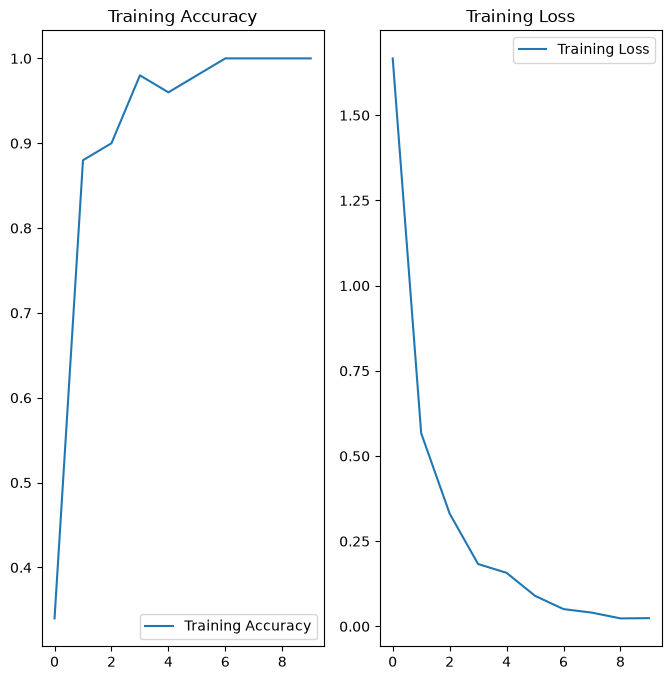

In [16]:
# Đánh giá model (train trên toàn bộ ảnh nên chỉ có đường Training)
acc = history.history['accuracy']
loss = history.history['loss']

epochs_range = range(epochs)

plt.figure(figsize=(8, 8))
plt.subplot(1, 2, 1)
plt.plot(epochs_range, acc, label='Training Accuracy')
plt.legend(loc='lower right')
plt.title('Training Accuracy')

plt.subplot(1, 2, 2)
plt.plot(epochs_range, loss, label='Training Loss')
plt.legend(loc='upper right')
plt.title('Training Loss')
plt.show()

Predict 3 - Hoa mai with a 88.22 percent confidence. 
 Path: Set_B\Test\3_HoaMai.jpg


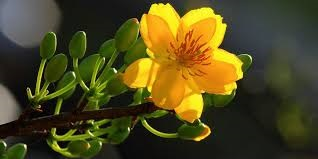

In [17]:
# hàm dự đoán 1 hình: lấy trung bình dự đoán của hình gốc và hình lật ngang -> ổn định hơn
def du_doan_hinh(duong_dan):
    img = tf.keras.utils.load_img(duong_dan, target_size=(img_height, img_width))
    img_array = tf.keras.utils.img_to_array(img)
    batch = tf.stack([img_array, tf.image.flip_left_right(img_array)])  # hình gốc + hình lật
    score = tf.reduce_mean(tf.nn.softmax(model.predict(batch, verbose=0)), axis=0)
    return img, class_names[np.argmax(score)], 100 * float(np.max(score))

#dự đoán 1 hình trong test (hình đầu tiên thuộc loài có trong tập train)
so_loai_train = [c.split(" ")[0] for c in class_names]
HinhDuDoan = next((p for p in testList if loai_that(p) in so_loai_train), testList[0])
img, du_doan, accuracy = du_doan_hinh(HinhDuDoan)

print(
    "Predict {} with a {:.2f} percent confidence. \n Path: {}"
    .format(du_doan, accuracy, HinhDuDoan)
)
PIL.Image.open(HinhDuDoan)

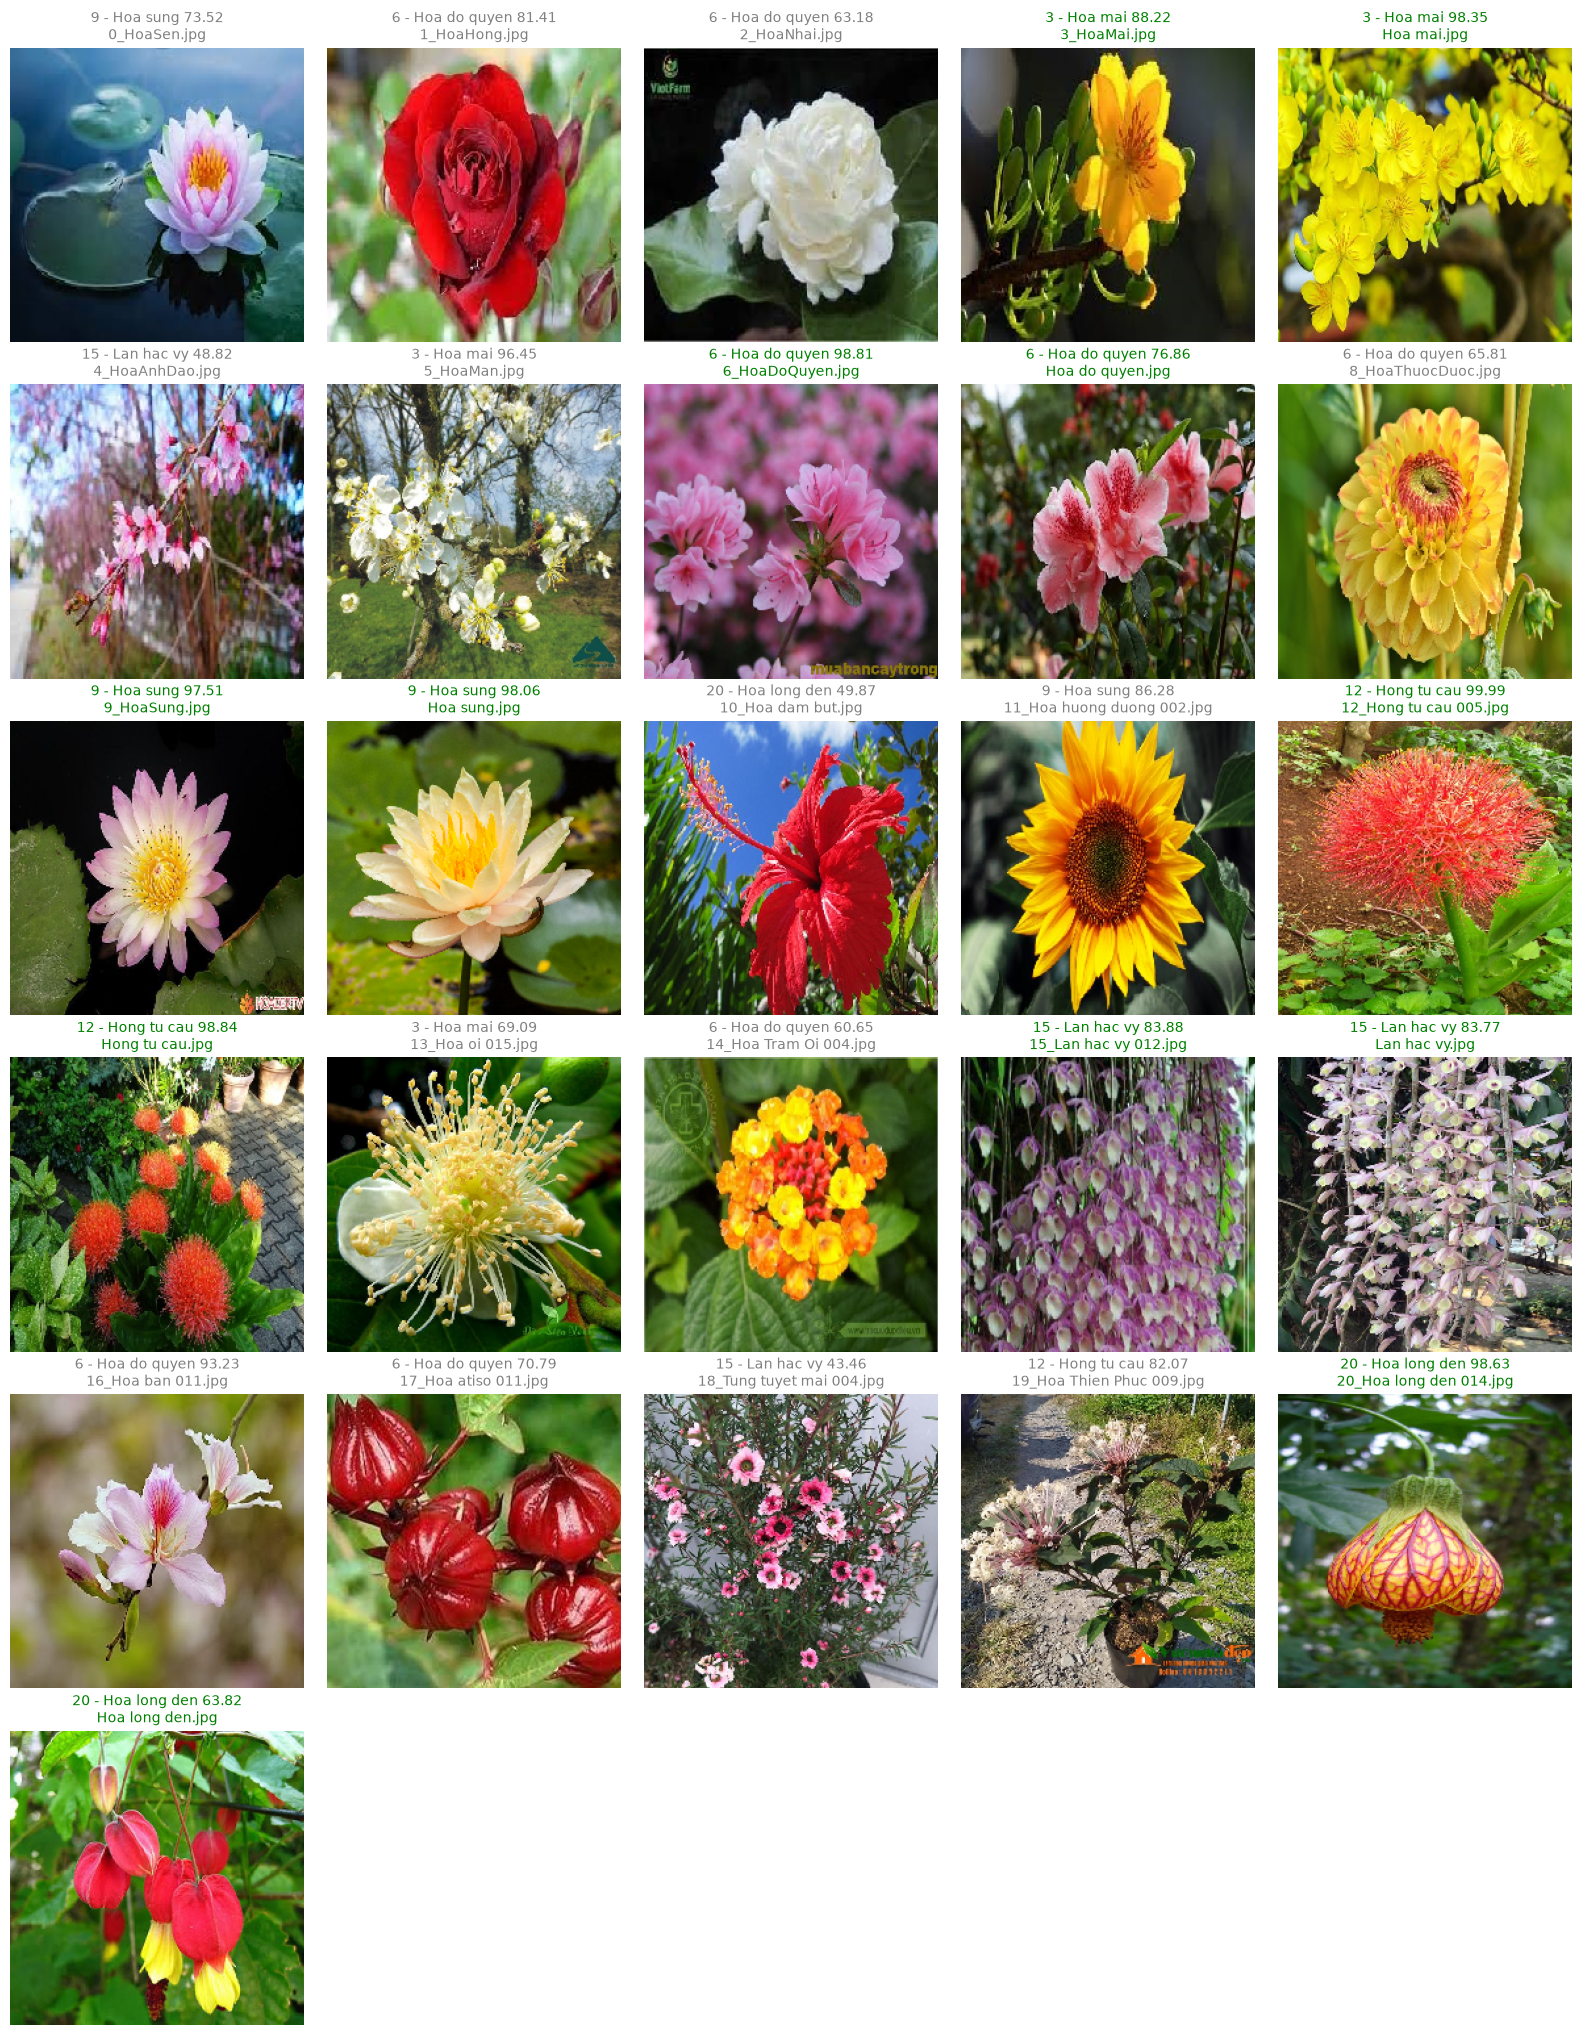

Set_B: số hình đoán đúng 12/26
  - hình của loài đã train: đúng 12/12
  - hình của loài chưa train (màu xám): 14 hình -> model không thể gọi đúng tên


In [18]:
## Full CODE predict
## Kết quả dự đoán: lưới 5 cột, mỗi ô = label dự đoán + accuracy, tên file

SO_COT = 5
SO_ANH_MOT_TRANG = 30   # tối đa 6x5 mỗi trang, nhiều hơn thì tự chia trang
so_loai = [c.split(" ")[0] for c in class_names]

def du_doan_nhieu(danh_sach):
    """Dự đoán cả danh sách (trung bình ảnh gốc + ảnh lật ngang)."""
    imgs = [tf.keras.utils.load_img(p, target_size=(img_height, img_width)) for p in danh_sach]
    arr = np.stack([tf.keras.utils.img_to_array(i) for i in imgs])
    p1 = tf.nn.softmax(model.predict(arr, verbose=0))
    p2 = tf.nn.softmax(model.predict(arr[:, :, ::-1, :], verbose=0))
    score = ((p1 + p2) / 2).numpy()
    return imgs, [class_names[i] for i in score.argmax(1)], 100 * score.max(1)

imgs, nhan, do_tin_cay = du_doan_nhieu(testList)

so_dung = 0
quen_dung = quen_tong = 0   # hình của loài có trong tập train
so_trang = math.ceil(len(testList) / SO_ANH_MOT_TRANG)
for trang in range(so_trang):
    bat_dau = trang * SO_ANH_MOT_TRANG
    ket_thuc = min(bat_dau + SO_ANH_MOT_TRANG, len(testList))
    so_hang = math.ceil((ket_thuc - bat_dau) / SO_COT)

    fig, axes = plt.subplots(so_hang, SO_COT, figsize=(16, 3.4 * so_hang), squeeze=False)
    for k, ax in enumerate(axes.flat):
        ax.axis("off")
        i = bat_dau + k
        if i >= ket_thuc:
            continue

        so_hinh = loai_that(testList[i])   # loài thật (theo số đầu tên file hoặc tên hoa)
        dung = nhan[i].split(" ")[0] == so_hinh
        so_dung += dung
        if so_hinh not in so_loai:
            mau = "gray"                      # loài không có trong dữ liệu train
        else:
            mau = "green" if dung else "red"
            quen_tong += 1
            quen_dung += dung

        ax.imshow(imgs[i])
        # dòng 1: label + accuracy, dòng 2: tên file
        ax.set_title("{} {:.2f}\n{}".format(nhan[i], do_tin_cay[i], testList[i].name),
                     fontsize=10, color=mau)

    plt.tight_layout()
    plt.savefig("./Result/Result-predicted-{}.png".format(TEN_SET, trang + 1))
    plt.show()

print("{}: số hình đoán đúng {}/{}".format(TEN_SET, so_dung, len(testList)))
print("  - hình của loài đã train: đúng {}/{}".format(quen_dung, quen_tong))
print("  - hình của loài chưa train (màu xám): {} hình -> model không thể gọi đúng tên".format(len(testList) - quen_tong))

In [19]:
#lưu model đã train

model.save("./Result/KQ-train.keras")